## 📋 과제 제출 정보

# 광고는 정말 구매 전환을 늘렸을까? — 마케팅 캠페인 A/B 테스트 분석

| 데이터셋     | [중] 마케팅 캠페인 A/B 테스트 데이터셋 |
| 데이터셋 출처 | https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing |
| 제출 링크    | https://github.com/____/ab-test-marketing |
| 과제명       | [통계적 검정과 인과추론] 종합 과제 - A/B 테스트 

| 분석자       | AI 데이터 인텔리전스 2기 박근아 
| 제출일       | 2026-11-08 

| 질문        | 광고(ad)를 본 사용자가 공익광고(psa)를 본 사용자보다 더 많이 구매 전환했는가?

**흐름 (6단계 고정)**
1 데이터 점검·전처리 → 2 질문·가설(결과 보기 전 고정) → 3 검정 선택 → 4 결과 분석(점추정·95% CI·p·효과크기) → 5 마케팅 의사결정(비용 민감도) → 6 보고서·한계

> 각 단계는 **지금 무엇을 하는가 → 왜 이 방법인가 → 무엇을 확인하고 어떻게 해석하는가** 

> ### 📒 이 데이터는 어떤 실험인가
>
> 한 마케팅 회사가 캠페인이 성공했는지, 성공했다면 **그중 얼마가 광고 덕분인지** 알고 싶어 한 실험이다. 사용자 대부분에게 **제품 광고**를(실험군), 일부에게 같은 자리·같은 크기로 **공익광고(PSA)** 를(대조군) 보여 줬다. 대조군도 광고 자리에 "무언가"를 보기 때문에, 두 집단의 차이를 **광고 내용 자체의 효과**로 볼 수 있다.
>
> | 컬럼             | 뜻                           | 분석에서의 역할 
> 
> | `Unnamed: 0`    | 저장할 때 생긴 행 번호          | 의미 없음 → 삭제 
> | `user id`       | 사용자 고유 번호               | 중복 확인 
> | `test group`    | `ad` / `psa`                 | **처치 변수** 
> | `converted`     | 구매 여부 (True/False)        | **결과 변수 (주 지표)** 
> | `total ads`     | 본 광고 수                    | 처치 이후 변수 → 통제하지 않음 
> | `most ads day`  | 광고를 가장 많이 본 요일        | 처치 이후 변수 → 원인 해석 안 함 
> | `most ads hour` | 광고를 가장 많이 본 시간 (0~23) | 처치 이후 변수 → 원인 해석 안 함 
>
> **시작 전에 알아 둘 것**
> 1. 주 분석은 `test group` × `converted`, 즉 **2×2 표 하나**로 끝난다. 나머지는 맥락과 점검용이다.
> 2. 약 96:4의 **불균형은 오류가 아니라 설계**다. 원래 계획 비율 정보가 없어 SRM은 판정 유보.
> 3. 표본이 거대해 **아주 작은 차이도 유의**하게 나올 수 있다. 그래서 효과크기와 비용 분석이 중요하다.

> ### 📒 "2×2 표 하나"와 "SRM 판정 유보"
>
> #### 1. 주 분석은 2×2 표 하나로 끝난다
>
> 이 과제의 질문은 **"광고를 봤느냐에 따라 구매가 달라졌나?"** 하나다. 여기에 필요한 컬럼은 두 개뿐이다.
>
> | 용어      | 내가 이해한 뜻                        | 이 데이터에서 
> 
> | 처치 변수 | 실험에서 **다르게 해 준 것** (원인 후보) | `test group`: 광고(ad) / 공익광고(psa) 
> | 결과 변수 | 그 결과로 **달라졌는지 보려는 것**       | `converted`: 구매함 / 안 함 
> | 주 분석   | 질문에 **직접 답하는 핵심 분석**        | 두 집단의 구매 비율 비교 
>
> **2×2 표(교차표)** 는 처치 변수 두 값과 결과 변수 두 값을 가로세로로 놓고 **사람 수를 센 네 칸짜리 표**다. 이 표만 있으면
> - 각 집단의 **전환율**(구매함 ÷ 합계)을 구하고,
> - 두 전환율의 차이가 **우연 이상인지 검정**하고,
> - 차이가 **얼마나 큰지(효과크기)** 까지 계산할 수 있다.
>
> 나머지 컬럼(`total ads`, `most ads day`, `most ads hour`)은 **맥락과 점검용**이다. 광고를 본 **뒤에** 생긴 값이라, 구매의 원인처럼 해석하거나 분석에 섞으면 안 된다.
>
> #### 2. 96:4의 불균형은 오류가 아니라 설계, SRM은 판정 유보
>
> | 용어                         | 내가 이해한 뜻 
> 
> | 불균형                       | 두 집단 크기가 크게 다름 (광고 96%, 공익광고 4%) 
> | 설계                         | 실험을 **처음부터 그렇게 하기로 계획한 것** 
> | 대조군                       | 비교 기준이 되는 집단 (여기선 psa) 
> | SRM (Sample Ratio Mismatch) | **계획한 비율과 실제 비율이 어긋난 것**. 배정 버그나 데이터 누락의 신호 
> | 판정 유보                    | 판단 근거가 없어 **정상/비정상을 말하지 않고 보류**하는 것 
>
> **왜 불균형이 오류가 아닌가** 공익광고를 보여 주는 건 광고 자리를 공짜로 내주는 손해다. 그래서 대부분에게 실제 광고를, 비교에 필요한 만큼만 소수에게 공익광고를 보여 줬다. **일부러 그렇게 나눈 것**이다.
>
> **크기가 달라도 검정은 괜찮은가** 괜찮다. 전환율은 **각 집단 안에서 따로** 계산하기 때문이다. 대신 대조군이 작으면 그쪽 전환율이 덜 정확해서 **결과의 불확실성이 커진다.**
>
> **왜 SRM을 판정하지 않는가** SRM은 **계획한 비율과 비교**해야 판단할 수 있는데, 이 데이터에는 계획 문서가 없다. 실제 결과(96:4)를 보고 "계획도 96:4였겠지"라고 정해 비교하면 **답을 보고 문제를 만든 셈(순환논리)** 이라 당연히 "일치"가 나온다. 그래서 정직하게 **판정을 유보하고 보고서 한계에 기록**한다.
>
> #### 한 줄 정리
> 1. 질문에 직접 답하는 건 **"누가 무엇을 봤나 × 구매했나" 네 칸짜리 표 하나**다.
> 2. 광고를 많이 보여 준 건 **일부러 그렇게 한 것**이고, 원래 계획을 모르니 **배정이 잘됐는지는 판단을 보류**한다.

## 0. 환경 준비

> 💡 **알아둘 것** 난수를 쓰지 않더라도 시드를 고정해 재현성을 보장합니다. 데이터는 `data/marketing_AB.csv`에 둡니다(원본 CSV는 GitHub에 올리지 않습니다).

> ### 📒 재현성, 시드, 데이터 위치 
                                                        
> | 재현성        | 누가 언제 다시 실행해도 **같은 결과**가 나오는 것                       
> | 시드(seed)    | 난수를 만드는 **출발 번호**. 고정하면 매번 같은 "무작위" 숫자가 나옴    
> | 이 노트북에서  | 난수를 쓰지 않아 시드는 **안전장치** (나중에 무작위를 추가할 때 대비)   
> | 데이터 위치    | 노트북은 `data/marketing_AB.csv`로 찾음. 어긋나면 `FileNotFoundError`   
> | CSV 미업로드  | **용량·라이선스** 때문. `.gitignore`로 제외, 받는 법은 `data/README.md` 
>
> **** 결과를 다시 만들 수 있어야 믿을 수 있고, 그러려면 시드와 파일 경로를 고정해 둔다.

In [48]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [49]:
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import (proportions_ztest, confint_proportions_2indep,
                                          proportion_confint, proportion_effectsize)

np.random.seed(42)
plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False
sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)
ALPHA = 0.05

# CSV 파일 업로드 확인

In [50]:
import os
print(os.getcwd())
print(os.listdir("data"))

c:\Users\shini\Data Intelligence\AIFFEL_LMS_개인학습\05_통계적 검정과 인과추론 [종합과제]\AB-TEST-Marketing
['marketing_AB.csv', 'README.md']


In [51]:
print(raw.shape)
print(raw.info())
print(raw["test group"].value_counts(normalize=True).round(4))
print(raw.groupby("test group")["converted"].mean().round(4))
print(raw["total ads"].describe().round(1))

(588101, 7)
<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Unnamed: 0     588101 non-null  int64
 1   user id        588101 non-null  int64
 2   test group     588101 non-null  str  
 3   converted      588101 non-null  bool 
 4   total ads      588101 non-null  int64
 5   most ads day   588101 non-null  str  
 6   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(4), str(2)
memory usage: 32.6 MB
None
test group
ad     0.96
psa    0.04
Name: proportion, dtype: float64
test group
ad     0.0255
psa    0.0179
Name: converted, dtype: float64
count    588101.0
mean         24.8
std          43.7
min           1.0
25%           4.0
50%          13.0
75%          27.0
max        2065.0
Name: total ads, dtype: float64


In [52]:
# 📒 원본 데이터 첫인상 확인
if "raw" not in globals():                      # 불러오기 셀을 아직 안 돌렸다면 여기서 불러옴
    raw = pd.read_csv("data/marketing_AB.csv")

print(raw.shape)
raw.info()
print("\n[배정 비율]");      print(raw["test group"].value_counts(normalize=True).round(4))
print("\n[그룹별 전환율]");  print(raw.groupby("test group")["converted"].mean().round(4))
print("\n[노출 수 분포]");   print(raw["total ads"].describe().round(1))

(588101, 7)
<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Unnamed: 0     588101 non-null  int64
 1   user id        588101 non-null  int64
 2   test group     588101 non-null  str  
 3   converted      588101 non-null  bool 
 4   total ads      588101 non-null  int64
 5   most ads day   588101 non-null  str  
 6   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(4), str(2)
memory usage: 32.6 MB

[배정 비율]
test group
ad     0.96
psa    0.04
Name: proportion, dtype: float64

[그룹별 전환율]
test group
ad     0.0255
psa    0.0179
Name: converted, dtype: float64

[노출 수 분포]
count    588101.0
mean         24.8
std          43.7
min           1.0
25%           4.0
50%          13.0
75%          27.0
max        2065.0
Name: total ads, dtype: float64


> ### 📒 전체 데이터로 본 첫 결과
>
> | 확인 항목           | 결과                            |                                                              
>
> | 결측치             | 7개 컬럼 모두 588,101 non-null    | **결측 없음**, 제거할 행 없음                     
> | 배정 비율          | ad 96% : psa 4%                  | 설계상 불균형 (계획 비율 정보 없어 SRM 판정 유보) 
> | 그룹별 전환율       | ad 2.55% vs psa 1.79%           | 차이 약 +0.77%p (아직 **검정 전**, 우연일 수도)   
> | 노출 수 평균·중앙값 | 평균 24.8 > 중앙값 13             | 소수의 큰 값이 평균을 끌어올림 → **오른쪽 꼬리**  
> | 노출 수 범위       | 최소 1 ~ 최대 2,065, 표준편차 43.7 | 극단적 헤비 유저 존재 → 삭제하지 않고 **유지**    
> | 메모리             | 32.6 MB                         | GitHub에 올리지 않는 이유 중 하나                 
>
> ****
> - 전환율을 **처음 본 지금**이 가장 위험한 순간이다. 가설·검정·유의수준·의사결정 규칙은 이 숫자를 보기 **전에** 템플릿 2단계에 이미 정해 두었으므로, 이제 **바꾸지 않는다.**
> - 평균이 중앙값보다 훨씬 크면 분포가 한쪽으로 치우친 것이다. 노출 수를 요약할 땐 **중앙값**이 더 대표적이다.
> - 노출 수는 광고를 본 **뒤에** 생긴 값이라 분석에서 통제하지 않는다.
>
> **** 데이터는 깨끗하고, 광고군 전환율이 더 높아 **보인다.** 그 차이가 우연인지는 4단계에서 검정한다.

In [53]:
sns.set_style("whitegrid")                     # ① 스타일 먼저
plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False     # ② 글꼴은 그 다음

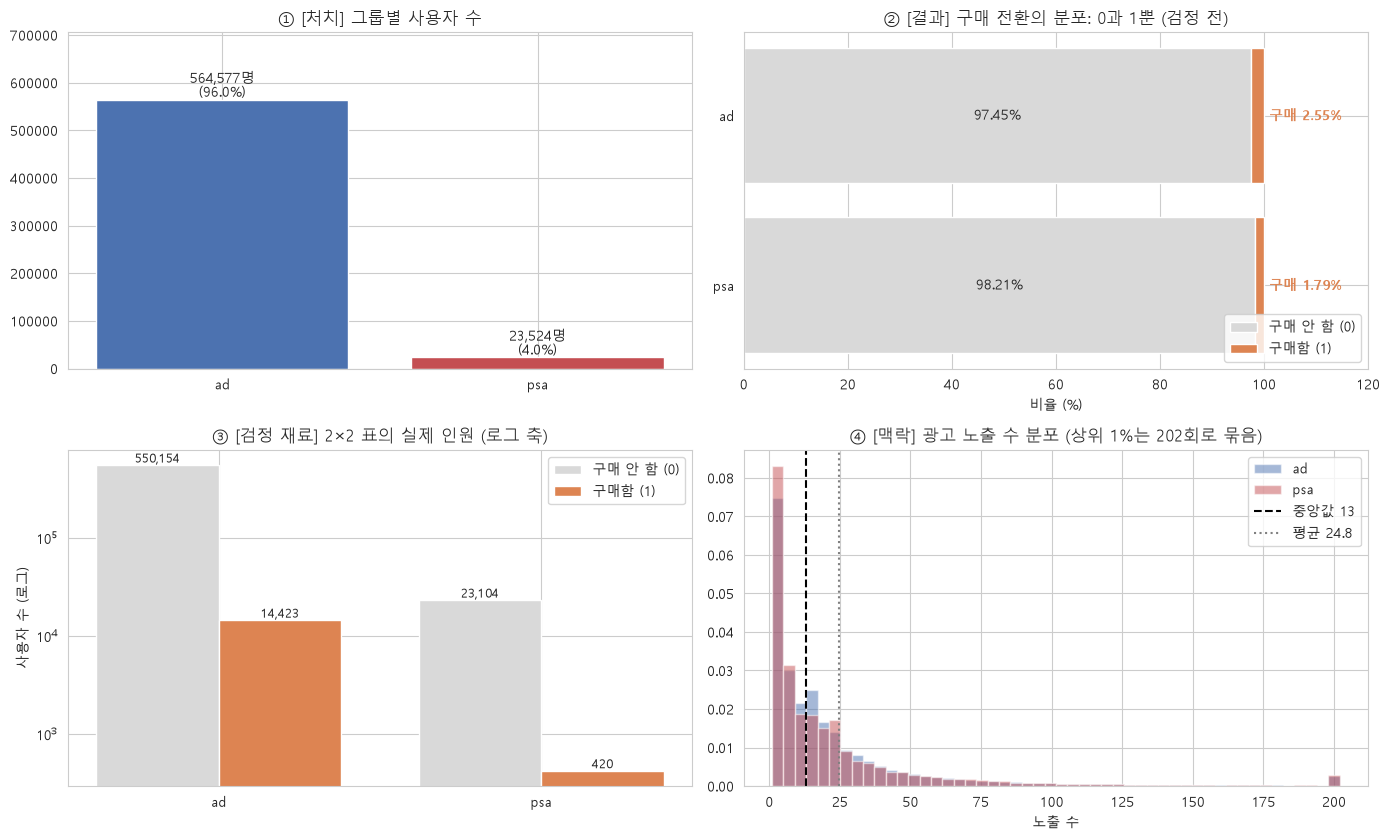

converted    False  True 
test group               
ad          550154  14423
psa          23104    420


In [54]:
# 첫인상 시각화: 핵심(처치 × 결과) 먼저, 맥락(노출 수)은 마지막
order  = ["ad", "psa"]
colors = {"ad": "#4C72B0", "psa": "#C44E52"}
tab   = pd.crosstab(raw["test group"], raw["converted"]).reindex(order)   # 2×2 표
share = tab.div(tab.sum(axis=1), axis=0) * 100
n     = tab.sum(axis=1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

# ① 처치: 그룹별 배정 규모
ax = axes[0, 0]
ax.bar(order, n, color=[colors[g] for g in order])
for i, g in enumerate(order):
    ax.text(i, n[g], f"{n[g]:,}명\n({n[g] / n.sum():.1%})", ha="center", va="bottom")
ax.set_ylim(0, n.max() * 1.25); ax.set_title("① [처치] 그룹별 사용자 수")

# ② 결과의 분포: 0/1 구성 (100% 누적)
ax = axes[0, 1]
ax.barh(order, share[False], color="#D9D9D9", label="구매 안 함 (0)")
ax.barh(order, share[True], left=share[False], color="#DD8452", label="구매함 (1)")
for i, g in enumerate(order):
    ax.text(share.loc[g, False] / 2, i, f"{share.loc[g, False]:.2f}%", ha="center", va="center")
    ax.text(101, i, f"구매 {share.loc[g, True]:.2f}%", ha="left", va="center", color="#DD8452", fontweight="bold")
ax.set_xlim(0, 120); ax.invert_yaxis(); ax.legend(loc="lower right")
ax.set_title("② [결과] 구매 전환의 분포: 0과 1뿐 (검정 전)"); ax.set_xlabel("비율 (%)")

# ③ 검정에 쓸 2×2 표: 실제 인원 (집단 크기 차이가 커서 로그 축)
ax = axes[1, 0]
x, w = np.arange(len(order)), 0.38
ax.bar(x - w/2, tab[False], w, color="#D9D9D9", label="구매 안 함 (0)")
ax.bar(x + w/2, tab[True],  w, color="#DD8452", label="구매함 (1)")
for i, g in enumerate(order):
    ax.text(i - w/2, tab.loc[g, False], f"{tab.loc[g, False]:,}", ha="center", va="bottom", fontsize=9)
    ax.text(i + w/2, tab.loc[g, True],  f"{tab.loc[g, True]:,}",  ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(order); ax.set_yscale("log"); ax.legend()
ax.set_title("③ [검정 재료] 2×2 표의 실제 인원 (로그 축)"); ax.set_ylabel("사용자 수 (로그)")

# ④ 맥락: 노출 수 분포 (처치 이후 변수, 검정 대상 아님 / 상위 1%는 그림에서만 묶음)
ax = axes[1, 1]
cap = raw["total ads"].quantile(0.99)
for g in order:
    s = raw.loc[raw["test group"] == g, "total ads"]
    ax.hist(s.clip(upper=cap), bins=50, density=True, alpha=0.5, color=colors[g], label=g)
ax.axvline(raw["total ads"].median(), color="black", ls="--", label=f"중앙값 {raw['total ads'].median():.0f}")
ax.axvline(raw["total ads"].mean(),   color="gray",  ls=":",  label=f"평균 {raw['total ads'].mean():.1f}")
ax.set_title(f"④ [맥락] 광고 노출 수 분포 (상위 1%는 {cap:.0f}회로 묶음)"); ax.set_xlabel("노출 수"); ax.legend()

plt.tight_layout()
plt.savefig("figures/first_look.png", dpi=150)
plt.show()
print(tab)

> ### 📒 첫인상 시각화 (처치 → 결과 → 검정 재료 → 맥락)
>
> | 칸          | 관찰                                   |                                             
> 
> | ① 처치      | ad 96% : psa 4% (psa 약 2만 4천 명)     | 설계상 불균형. **대조군이 작다 = 불확실성의 원천** 
> | ② 결과      | 두 집단 모두 97~98%가 구매 안 함          | 결과는 **0과 1뿐**이라 꼬리·극단값이 없음          
> |             | 구매 ad 2.55% vs psa 1.79%             | 광고군이 높아 **보임** (검정 전, 우연일 수도)      
> | ③ 검정 재료 | psa 구매자는 수백 명 수준                 | 대조군 전환율이 덜 정확 → 신뢰구간이 넓어지는 쪽   
> | ④ 맥락      | 노출 수 오른쪽 꼬리, 평균 24.8 > 중앙값 13 | 소수의 헤비 유저가 평균을 끌어올림 (최대 2,065회)  
> |             | 그림 끝 약 202회                        | 상위 1%를 묶어 그린 값일 뿐, **실제 최대값 아님**  
>
> **②와 ④를 나란히 보면** 치우친 건 **노출 수**이고, 검정하는 건 **0/1 구매 여부**다. 검정 방법은 **결과 변수의 형태**로 고르므로,
> - 노출 수가 치우쳤다고 **비모수 검정으로 바꾸지 않는다.** 비모수 검정은 연속형 결과가 정규분포가 아닐 때의 대안이다.
> - 노출 수 극단값을 **지우지 않는다.** 많이 본 사람도 실제 실험 참가자이고, 지우면 무작위로 나눈 균형이 깨질 수 있다.
> - 노출 수는 광고를 본 **뒤에** 생긴 값이라 구매와의 관계를 **인과로 해석하지 않는다.**
>
> **배운 점**
> - 시각화는 **핵심(처치 × 결과)부터**, 맥락은 나중에. 결과 변수의 분포를 빼먹으면 검정 선택의 근거가 비어 버린다.
> - 로그 축은 눈금 한 칸이 10배라 **막대 높이를 크기 차이로 읽으면 안 된다.**
> - 그림의 끝값은 그리는 방식(상위 1% 묶음)에 따라 달라지니, 정확한 수치는 **요약 통계로 확인**한다.
>
> **** 광고군의 전환율이 더 높아 보이지만 아직 검정 전이고, 결과가 0/1이니 **두 비율 검정**으로 확인한다.

> ### 📒 그래프를 읽을 때 속지 않는 법
>
> #### 1. 로그 축: 막대 높이 ≠ 크기 차이
>
> | 축      | 눈금 간격                 | 특징                           |
> |---------|---------------------------|--------------------------------|
> | 일반 축 | 0 → 10 → 20 → 30          | 한 칸마다 **같은 양**이 늘어남 |
> | 로그 축 | 10 → 100 → 1,000 → 10,000 | 한 칸마다 **10배**씩 늘어남    |
>
> **왜 썼나** ③번 그림에서 ad 비구매자(약 55만 명)와 psa 구매자(수백 명)를 일반 축에 그리면, 작은 막대들은 바닥에 붙어 아예 안 보인다. 로그 축은 큰 값과 작은 값을 **한 그림에 함께 보이게** 해 준다.
>
> **대가** 대신 차이가 실제보다 **작아 보인다.**
>
> | 비교                    | 로그 축에서 보이는 모습 | 실제 크기                                      |
> |------------------------|----------------------|------------------------------------------------|
> | psa 구매자 vs ad 구매자  | 높이 차이가 작아 보임   | 약 **30배** 차이 (수백 명 vs 약 1만 4천 명)    |
> | ad 구매자 vs ad 비구매자 | 높이 차이가 작아 보임   | 약 **40배** 차이 (약 1만 4천 명 vs 약 55만 명) |
>
> 그래서 로그 축 그림은 **"있다/없다, 어느 쪽이 큰가"** 를 보는 용도로 쓰고, **"몇 배 차이인가"** 는 막대 위에 적힌 숫자로 읽는다.
>
> #### 2. 그림의 끝값 ≠ 실제 최대값
>
> ④번 그림의 노출 수는 끝이 **약 202회**로 보이지만, 실제 최대값은 **2,065회**다. 극단값 때문에 그림이 찌그러지지 않도록 **상위 1%를 202회로 묶어서** 그렸기 때문이다. 데이터는 그대로이고, **그리는 방식만** 바꾼 것이다.
>
> 그래서 그림은 **모양(치우침, 꼬리)** 을 보는 용도로 쓰고, 정확한 값(최소·중앙값·평균·최대)은 `describe()` 같은 **요약 통계**로 확인한다.
>
> **** 그림은 **모양**을, 숫자는 **크기**를 말한다. 축과 제목의 조건(로그 축, 상위 1% 묶음)을 먼저 읽고 그림을 본다.

## 1. 데이터 점검·전처리 (검정보다 먼저!)

**무엇을** 결측·중복·라벨·값의 범위·배정 비율을 확인하고, 제외한 데이터는 이유와 함께 기록합니다.
**왜** 오염된 데이터 위의 p값은 의미가 없기 때문입니다.

> ❓ **내가 물어볼 질문**
> - 행 수·컬럼·자료형·결측치는?
> - 같은 사용자가 두 번 이상 나오나?
> - 그룹 라벨은 ad / psa 두 개뿐인가? 값의 범위는 상식적인가?
> - 배정 비율은 **원래 계획**대로인가? 원래 계획을 알 수 있나?

In [55]:
raw = pd.read_csv("data/marketing_AB.csv")
print("원본 크기:", raw.shape)
print(raw.dtypes)
raw.head()

원본 크기: (588101, 7)
Unnamed: 0       int64
user id          int64
test group         str
converted         bool
total ads        int64
most ads day       str
most ads hour    int64
dtype: object


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


> ### 📒 원본 데이터 첫인상
>
> | 보이는 것               | 의미                               | 다음에 확인할 것           
> |------------------------|-----------------------------------|--------------------------
> | 588,101행 × 7열        | 한 행 = 사용자 1명, 약 59만 명        | 중복 사용자는 없는가       
> | `Unnamed: 0`           | 0부터 시작하는 행 번호 (저장 흔적)    | 삭제                       
> | `converted` = bool     | 구매 여부가 True/False로 저장됨      | 0/1로 바꿔 평균 = 전환율   
> | `test group` = str     | ad / psa 문자 라벨                 | 라벨이 두 개뿐인가, 비율은 
> | `total ads` 21~355     | 사람마다 본 광고 수 차이가 매우 큼    | 분포 (극단값, 치우침)      
> | 첫 5행이 모두 ad·False | ad가 압도적 다수, 구매는 드묾          | 전체 배정 비율과 전환율    
> | 컬럼명에 공백          | `df["test group"]`처럼 써야 해서 불편 | 밑줄로 이름 정리           
>
> **** `head()`는 맨 위 5행만 보여 준다. 전체를 대표하지 않으므로, 판단은 반드시 **전체 집계**(비율·평균·분포)로 한다.
>
> **** 크기와 자료형은 예상대로다. 이제 결측·중복·라벨·비율·분포를 **전체 데이터로** 확인한다.

In [56]:
# 컬럼 이름 정리(공백 → 밑줄), 저장용 인덱스 컬럼 제거
df = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")]).copy()
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
print(df.columns.tolist())

print("\n[결측치]");          print(df.isna().sum())
print("\n[그룹 라벨]");       print(df["test_group"].value_counts())
print("\n[converted 값]");    print(df["converted"].value_counts())
print("\n[중복 사용자 ID 수]", df["user_id"].duplicated().sum())
print("[값 범위] total_ads 최소", df["total_ads"].min(), "/ most_ads_hour", df["most_ads_hour"].min(), "~", df["most_ads_hour"].max())
print("[요일 값]", sorted(df["most_ads_day"].unique()))

['user_id', 'test_group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']

[결측치]
user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64

[그룹 라벨]
test_group
ad     564577
psa     23524
Name: count, dtype: int64

[converted 값]
converted
False    573258
True      14843
Name: count, dtype: int64

[중복 사용자 ID 수] 0
[값 범위] total_ads 최소 1 / most_ads_hour 0 ~ 23
[요일 값] ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']


> ### 📒 데이터 위생 점검 결과
>
> | 점검        | 결과                                           | 판단                                  |
> |-------------|-----------------------------------------------|---------------------------------------|
> | 컬럼명      | 공백 → 밑줄 (`test_group` 등), `Unnamed: 0` 삭제 | 코드에서 쓰기 편해짐                  |
> | 결측치      | 6개 컬럼 모두 0                                 | ✅ 제거할 행 없음                     |
> | 그룹 라벨   | ad 564,577 / psa 23,524 (두 개뿐)               | ✅ 이상한 라벨 없음                   |
> | 구매 여부   | True 14,843 / False 573,258                    | ✅ 두 값뿐, 전체 전환율 약 2.52%      |
> | 중복 사용자 | 0명                                             | ✅ 한 사람이 두 집단에 섞인 경우 없음 |
> | 값 범위     | 노출 수 최소 1, 시간 0~23                        | ✅ 음수·불가능한 값 없음              |
> | 요일 값     | 월~일 7개                                       | ✅ 오타·이상값 없음                   |
>
> **** 중복 사용자 확인이 중요한 이유는, 같은 사람이 ad와 psa 양쪽에 들어가 있으면 **어느 집단의 효과인지 알 수 없기** 때문이다. 0명이므로 배정이 사람 단위로 깔끔
> **** 점검 결과 **제외할 데이터가 없다.** 원본 그대로 분석에 쓴다.

In [57]:
# 정제: 중복 사용자 제외(있다면), converted를 0/1로
n_before = len(df)
df = df.drop_duplicates(subset="user_id", keep=False)   # 두 번 이상 나온 사용자는 배정이 모호하므로 모두 제외
df = df[df["test_group"].isin(["ad", "psa"])]           # 예상 밖 라벨 제외
df["converted"] = df["converted"].astype(int)
n_after = len(df)
print(f"정제 전 {n_before:,}행 → 정제 후 {n_after:,}행 (제외 {n_before - n_after:,}행)")

정제 전 588,101행 → 정제 후 588,101행 (제외 0행)


> ✍️ **메모** 제외 0행, 이유: "점검 결과 제외 대상 없음"

### 1-1. 배정 비율과 SRM

**무엇을**     : 두 그룹의 실제 비율을 확인합니다.
**왜**         : 배정이 계획과 다르면(SRM) 배정 로직이나 로깅의 오류를 의심해야 하기 때문입니다.
**어떻게 해석** : SRM 검정은 **p가 커야 정상**입니다. 그런데 SRM은 **원래 계획한 비율과 비교**해야만 판단할 수 있습니다.

> ⚠️ 이 데이터는 50:50 실험이 아니라 대부분에게 광고를 보여 준 설계입니다. **불균형 자체는 오류가 아닙니다.** 원래 계획한 비율을 알려 주는 문서가 없으므로, 관측된 비율로 '기대 비율'을 만들어 검정하는 것은 순환논리입니다. 따라서 **SRM 판정은 유보**하고 한계에 기록합니다.

> ### 📒 배정 비율과 SRM, 한눈에
>
> **학습자로서 이해한 것** SRM 점검은 **"계획대로 나눴나?"** 를 확인하는 일이다. 그러려면 **계획**과 **실제**를 비교해야 한다.
>
> | 상황       | 계획    | 실제   | 판단                              
> |-----------|-------- |-------|--------------------------------
> | 보통의 A/B | 50:50   | 60:40 | 어긋남 → **배정 오류 의심**        
> | 이 데이터  | **모름** | 96:4  | 비교할 기준이 없음 → **판정 유보** 
>
> - 96:4라는 불균형은 **일부러 그렇게 나눈 설계**라서 그 자체로는 오류가 아니다.
> - 실제 비율(96:4)을 보고 "계획도 96:4였겠지"라고 정해 비교하면, **답을 보고 채점하는 셈**이라 의미가 없다.
>
> ****
> 1. 실제 비율을 **기록**한다 (ad 564,577 : psa 23,524).
> 2. 계획 비율을 모르니 **SRM은 판정하지 않는다.**
> 3. 이 사실을 보고서 **한계**에 적고, 이후 결과는 **"배정이 적절했다는 전제 하에서"** 해석한다.
>
> **** 기준(계획)이 없으면 채점(판정)도 없다. 모르는 건 모른다고 기록한다.

In [58]:
n_ad, n_psa = (df["test_group"] == "ad").sum(), (df["test_group"] == "psa").sum()
total = n_ad + n_psa
print(f"ad {n_ad:,} ({n_ad/total:.1%})  |  psa {n_psa:,} ({n_psa/total:.1%})")

# 참고: 50:50을 기대 비율로 두면? → 이 실험의 계획과 맞지 않으므로 판정 근거로 쓰지 않는다
print("참고) 50:50 기대 시 SRM p =", stats.chisquare([n_ad, n_psa], [total/2, total/2]).pvalue)

ad 564,577 (96.0%)  |  psa 23,524 (4.0%)
참고) 50:50 기대 시 SRM p = 0.0


> ✍️ **메모** 관측 비율 ad 96.0% : psa 4.0%. 원래 배정 계획 정보가 없어 **SRM 판정 유보**. 무작위 배정이 적절했다는 **전제 하에서** 이후 결과를 인과적으로 해석한다.

> ### 📒 왜 "인과적으로" 해석, 왜 "전제 하에서"인가
>
> | 해석      | 말할 수 있는 것                 | 의사결정에 쓸 수 있나               |
> |---------- |------------------------------|-------------------------------------|
> | 연관(상관) | "광고군의 전환율이 더 높았다"    | ❌ 광고를 집행할지 판단할 근거 부족 |
> | 인과      | "광고가 전환율을 약 __%p 높였다" | ✅ 광고 집행 여부를 판단할 수 있음  |
>
> 1. **질문이 인과적** "광고를 보여 주면 구매가 늘어나는가"는 *바꾸면 달라지는가*를 묻는 개입(2계단) 질문
> 2. **A/B 설계가 인과 해석을 허락한다.** 무작위 배정이면 두 집단은 광고 여부만 다르므로, 차이를 광고의 효과로 볼 수 있다.
> 3. **그 조건을 확인할 수 없다.** 배정 점검(SRM)에 필요한 계획 비율이 없다. **"배정이 적절했다는 전제 하에서"**
>
> **참고** 출력의 `50:50 기대 시 SRM p = 0.0`은 이 실험의 설계(50:50 아님)와 맞지 않아 판정 근거로 쓰지 않는다. `0.0`은 정확히 0이 아니라 너무 작아 0으로 표시된 값이다.
>
> **** 결정을 하려면 인과가 필요하고, 인과를 말하려면 그 조건을 밝혀야 한다.

### 1-2. 처치 이후 변수 확인 (`total_ads`, `most_ads_day`, `most_ads_hour`)

**무엇을** 광고 노출 수와 노출 요일·시간의 분포를 봅니다.
**왜** 이 변수들은 **배정 이후의 행동**에서 생긴 값입니다. 결과와 함께 움직일 수 있어 **통제 변수로 넣으면 안 되고**(나쁜 통제), 특정 요일·시간이 구매의 원인이라고 결론 내려서도 안 됩니다.
**어떻게** 주 분석은 **배정된 그룹 그대로** 비교합니다(ITT). 극단값은 실제 헤비 유저일 수 있어 **삭제하지 않고 유지**합니다.

               count  mean   std  min  25%   50%   75%     max
test_group                                                    
ad          564577.0  24.8  43.8  1.0  4.0  13.0  27.0  2065.0
psa          23524.0  24.8  42.9  1.0  4.0  12.0  26.0   907.0


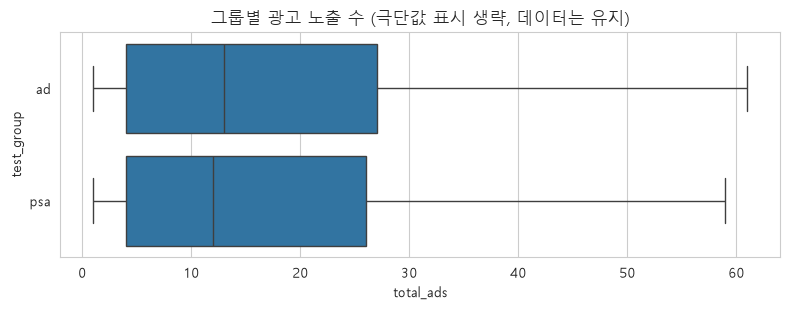

In [59]:
print(df.groupby("test_group")["total_ads"].describe().round(1))
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.boxplot(data=df, x="total_ads", y="test_group", ax=ax, showfliers=False)
ax.set_title("그룹별 광고 노출 수 (극단값 표시 생략, 데이터는 유지)")
plt.tight_layout(); plt.show()

> ### 📒 그룹의 광고 노출 수 비교
>
> | 통계      | ad     | psa    |                                                     
> 
> | 최대      | 2,065  | 907    | 차이 큼. 단, **사람 수가 많을수록 극단값이 나올 기회도 많음** 
>
> ****
> - 두 그룹은 **광고 자리에 노출된 횟수가 사실상 같다.** psa 그룹도 같은 자리, 같은 횟수로 공익광고를 봤다는 뜻이다.
> - 최대값 차이는 그룹 크기 차이(약 56만 명 vs 약 2만 4천 명) 때문일 가능성이 크다. 사람이 많으면 아주 많이 본 사람도 나올 확률이 커진다. 그래서 극단값보다 **중앙값과 사분위**로 비교한다.
>
> ****
> - 노출량이 두 그룹에서 비슷하다는 건, 두 그룹이 **"무엇을 봤는가(광고 vs 공익광고)"만 다르고 "얼마나 봤는가"는 같다**는 간접 근거다. 무작위 배정이 적절했다는 전제와도 어긋나지 않는다. (증명은 아니다.)
> - 그래도 노출 수는 배정 **이후**에 생긴 값이므로 **통제 변수로 넣지 않고**, 주 분석은 **배정된 그룹 그대로(ITT)** 비교한다.
> - 극단값은 실제 헤비 유저일 수 있어 **삭제하지 않는다.**
>
> **** 두 그룹은 노출량이 같고 내용만 다르다. 전환율 차이를 **광고 내용의 효과**로 읽을 근거가 하나 더 생겼다.

## 2. 질문과 가설 — 결과를 보기 전에 고정

> ⚠️ 여기서 정한 가설·검정·유의수준·**의사결정 규칙**은 결과를 본 뒤 바꾸지 않습니다(바꾸면 p-해킹).

- **질문:** 광고가 공익광고 대비 구매 전환율을 높였는가?
- **주 지표:** 구매 전환율 (`converted`, 0/1)
- **H₀:** 광고군과 공익광고군의 전환율은 같다. (p_ad = p_psa)
- **H₁:** 두 그룹의 전환율은 다르다. (p_ad ≠ p_psa)
- **유의수준 α = 0.05, 양측 검정.** 광고가 오히려 전환을 낮출 가능성도 열어 둔다.

**의사결정 규칙(미리 정함)** 5단계에서 계산할 **손익분기 상승폭**을 기준으로,
- 95% 신뢰구간 **하한**이 손익분기 이상 → **출시**
- 점추정은 손익분기 이상이지만 하한은 미만 → **추가 수집**
- 점추정이 손익분기 미만, 또는 차이가 유의하지 않음 → **보류**

> ### 📒 
>
> | 손익분기 상승폭   | 광고비 대비 전환율이 최소 몇 %p 올라야 하는가 
> | 점추정           | 실험이 알려 준 **가장 그럴듯한** 상승폭                      
> | 95% 신뢰구간 하한 | **보수적으로 봐도** 최소 이만큼은 올랐다고 할 수 있는 값     
>
> | 경우                                | (▼ = 손익분기)             | 결정         | 이유                       |
> |------------------------------------|---------------------------|--------------|----------------------------|
> | ① 하한 ≥ 손익분기                    | ▼ [하한 ── 점추정 ── 상한]  | **출시**      | 나쁘게 봐도 이익           |
> | ② 점추정 ≥ 손익분기 > 하한            | [하한 ─ ▼ ─ 점추정 ── 상한] | **추가 수집** | 이익일 것 같지만 확신 부족 |
> | ③ 점추정 < 손익분기, 또는 유의하지 않음 | [하한 ── 점추정 ─ ▼ ─ 상한] | **보류**     | 이익이라고 볼 근거 부족    |
>
> **하한을 기준으로 출시
> **** "유의한가"가 아니라 **하한을 넘는가"** 로 결정

## 3. 검정 고르기 ⭐

> ❓ **내가 물어볼 질문 세 가지** ① 지표가 비율인가 연속형인가? ② 집단이 2개인가? ③ (연속형이면) 정규성·등분산은?

**나는 두 비율 z-검정(= 2×2 카이제곱 독립성 검정)을 골랐다.** 왜냐하면 주 지표 `converted`가 **구매했다/안 했다의 비율**이고, 비교 집단이 **ad와 psa 두 개**이기 때문이다. 비율 지표라 정규성·등분산 가정은 필요 없고, 대신 각 칸의 도수가 충분해야 하는데(전환·비전환 모두 10 이상) 아래에서 확인한다. z-검정은 차이의 **방향과 신뢰구간**을 바로 주고, 카이제곱과는 χ² = z²로 같은 결론이므로 효과크기(Cramér's V) 계산에 함께 쓴다. 그룹 크기가 크게 다르지만, 두 비율 검정은 각 그룹의 표본 수를 따로 반영하므로 불균형 자체가 검정을 무효로 만들지는 않는다. 다만 불확실성은 주로 **작은 쪽(psa)** 에서 온다.

> ### 📒 

> | 확인할 점         | 내용                                                                          
> |------------------|---------------------------------------------------------------------
> | 조건             | 2×2 표의 네 칸 모두 **10명 이상**이어야 함                                    
> | z-검정을 쓰는 이유 | 차이의 **방향**과 **신뢰구간**을 바로 줌                                      
> | 카이제곱과의 관계  | χ² = z² 로 **같은 결론**. 효과크기(Cramér's V) 계산에 사용                    
> | 그룹 크기 불균형   | 각 그룹 표본 수를 따로 반영해 **검정은 유효**. 불확실성은 작은 쪽(psa)에서 옴 
>
> **** 결과가 0/1이고 집단이 2개면 **두 비율 검정**이다.

> ### 📒 네 칸 모두 10명 이상이어야
>
> **핵심** z-검정은 전환율의 흔들림이 **정규분포(종 모양)를 따른다고 보고** p값을 계산한다. 이 가정은 각 칸에 사람이 **충분히 있을 때만** 잘 맞는다.
>
> | 칸 안의 사람 수    | 구매자 수의 분포 모양         | 정규분포 근사  | p값            |
> |------------------|----------------------------|--------------|----------------|
> | 적음 (예: 3명)    | 0 쪽에 몰리고 한쪽으로 치우침  | ❌ 잘 안 맞음 | 부정확할 수 있음 |
> | 충분함 (10명 이상) | 좌우가 고른 종 모양에 가까워짐 | ✅ 잘 맞음    | 믿을 만함       |
>
> **** 중심극한정리** 표본이 커지면 원래 모양과 상관없이 평균(여기선 전환율)의 분포가 **종 모양**에 가까워진다. 칸마다 사람이 충분해야 하는 이유
>
> **10이라는 숫자** 정확한 경계가 아니라 **관례적인 기준(경험칙)** 이다. 엄밀히는 *기대* 도수로 따지며, 카이제곱에서는 5 이상을 쓰기도 한다.
> **기준을 못 넘으면** 정규분포 근사 대신 정확한 확률을 직접 계산하는 **피셔의 정확 검정**을 쓴다.
> **이 데이터에서는** 가장 작은 칸(psa 구매자)도 수백 명이라 기준을 **여유 있게** 넘는다.

> **** 사람이 충분해야 종 모양 근사가 맞고, 그래야 z-검정의 p값을 믿을 수 있다.
> ****
>
> | 상황                          | 문제                            | 대응                                      |
> |------------------------------|---------------------------------|------------------------------------------|
> | 출시 첫날 구매자 5명            | 칸이 작아 z-검정 p값을 믿기 어려움  | 피셔 정확 검정, 또는 미리 정한 표본까지 기다림 |
> | 세그먼트를 잘게 쪼갬 (VIP·지역별)| 칸마다 구매자가 몇 명뿐            | 세그먼트 수를 줄이거나 정확 검정              |
> | 전환율이 아주 낮은 상품         | 표본이 커도 구매자 칸이 작을 수 있음 | 검정 전 2×2 표의 칸 크기부터 확인            |
>
> **** 전체 표본이 커도 **가장 작은 칸**이 기준이다. 검정 전에 2×2 표부터 본다.

In [60]:
ct = pd.crosstab(df["test_group"], df["converted"])
print(ct)
print("모든 칸 ≥ 10 ?", (ct.values >= 10).all())

converted        0      1
test_group               
ad          550154  14423
psa          23104    420
모든 칸 ≥ 10 ? True


> ### 📒 검정의 재료, 2×2 표
>
> | test_group | 구매 안 함 (0) | 구매함 (1) | 합계     | 전환율  |
> |------------|---------------|-----------|---------|--------|
> | ad         | 550,154       | 14,423    | 564,577 | 2.55%  |
> | psa        | 23,104        | **420**   | 23,524  | 1.79%  |
>
> | 파악할 것      | 내용                                                              
> |---------------|------------------------------------------------------------------
> | 조건 충족      | 가장 작은 칸(psa 구매자)도 **420명** ≫ 10 → `True`, z-검정 사용 가능  
> | 표의 역할      | 이 네 숫자가 이후 **모든 계산의 재료** (전환율, z, 신뢰구간, 효과크기)    
> | 읽는 법        | 전환율 = 구매함 ÷ 합계. 행끼리 비교해야 함 (ad 안에서, psa 안에서)      
> | 불확실성의 원천 | ad 구매자는 1만 4천 명, psa 구매자는 420명 → **신뢰구간 폭은 주로 psa가 결정** 

> ### 📒
> 차이(ad − psa)의 흔들림은 **두 전환율의 흔들림이 합쳐진 것**이고, 사람이 적은 쪽이 훨씬 많이 흔들린다.
>
> |                         | ad        | psa                   
> |-------------------------|---------- |-----------------------
> | 사람 수                  | 564,577명 | 23,524명              
> | 전환율의 흔들림 (표준오차)  | ±0.021%p | ±0.086%p (**약 4배**) 
> | 차이의 흔들림에 기여하는 몫 | 약 6%     | **약 94%**            
>
> 신뢰구간은 약 ±0.17%p인데, ad를 무한히 모아도 거의 그대로다. **폭은 거의 전부 psa에서 온다.**
>
> **🔁** 표준오차는 √n에 반비례. 사람이 적으면 평균(전환율)이 더 크게 흔들린다.
> **** 결과를 더 정확하게 하려면 광고군이 아니라 **대조군을 늘려야** 한다. 다만 대조군이 커질수록 광고를 못 보여 주는 **기회비용**도 커지므로, 그 균형을 정하는 것이 실험 설계다.
> **** 정확도는 **가장 작은 집단**이 정한다.
> **🔁** 전체 표본은 58만 명이지만, 검정의 정확도를 좌우하는 건 **가장 작은 칸**이다. 이 데이터에선 그 칸도 충분히 크다.
> **** 네 칸이 모두 충분하니 **두 비율 z-검정**을 그대로 쓴다. 이제 이 표로 결과를 계산한다.

## 4. 결과 분석 — 점추정 · 95% 신뢰구간 · p값 · 효과크기

**무엇을** 차이의 크기, 불확실성, 유의성, 효과크기를 함께 계산합니다.
**왜** p값은 "우연인가"만 말해 줍니다. "얼마나 큰가"는 점추정·신뢰구간·효과크기가 말해 줍니다.
**어떻게 해석** 비율 지표는 **절대 차이(%p)와 상대 차이(배수)를 둘 다** 적습니다. 상대 차이만 쓰면 과장되고, 절대 차이만 쓰면 작아 보입니다.

In [61]:
c_ad  = df.loc[df.test_group == "ad",  "converted"].sum()
c_psa = df.loc[df.test_group == "psa", "converted"].sum()
p_ad, p_psa = c_ad / n_ad, c_psa / n_psa
lift = p_ad - p_psa

z, p_z = proportions_ztest([c_ad, c_psa], [n_ad, n_psa])
lo, hi = confint_proportions_2indep(c_ad, n_ad, c_psa, n_psa, method="wald")
chi2, p_chi, dof, _ = stats.chi2_contingency(ct, correction=False)
cramers_v = np.sqrt(chi2 / ct.values.sum())
cohens_h = proportion_effectsize(p_ad, p_psa)

print(f"전환율        ad {p_ad:.3%}  vs  psa {p_psa:.3%}")
print(f"① 절대 차이   {lift*100:+.2f}%p   95% CI [{lo*100:+.2f}, {hi*100:+.2f}]%p")
print(f"   상대 차이   {p_ad / p_psa:.2f}배  ({(p_ad / p_psa - 1)*100:+.0f}%)")
print(f"② 검정        z = {z:.2f}, p = {p_z:.2e}   |   χ²({dof}) = {chi2:.1f}")
print(f"③ 효과크기    Cramér's V = {cramers_v:.3f},  Cohen's h = {cohens_h:.3f}")

전환율        ad 2.555%  vs  psa 1.785%
① 절대 차이   +0.77%p   95% CI [+0.60, +0.94]%p
   상대 차이   1.43배  (+43%)
② 검정        z = 7.37, p = 1.71e-13   |   χ²(1) = 54.3
③ 효과크기    Cramér's V = 0.010,  Cohen's h = 0.053


> ### 📒 결과 읽기: 유의하지만 작다?
>
> #### 결과
>
> | 숫자                      | 값               |                                                   |
> |------------------------- |------------------|---------------------------------------------------|
> | ① 절대 차이               | +0.77%p          | 광고군이 100명당 약 **0.77명** 더 구매                |
> | 95% 신뢰구간              | [+0.60, +0.94]%p | 차이는 대략 이 범위. **0을 포함하지 않음**             |
> | 상대 차이                 | 1.43배 (+43%)    | 대조군보다 전환율이 **43% 높음** (같은 결과의 다른 표현) |
> | ② z / p                  | 7.37 / 1.71e-13  | 우연이라면 거의 나올 수 없는 차이 → **H₀ 기각**        |
> | χ²(1)                    | 54.3             | z² = 7.37² ≈ 54.3, **같은 결론**                   |
> | ③ Cramér's V / Cohen's h | 0.010 / 0.053    | 효과크기 기준(0.1·0.2)으로 **아주 작음**             |
>
> #### 
>
> | 관점                      | 숫자      |                                               |
> |--------------------------|-----------|-------------------------------------------------------|
> | 통계 (효과크기)            | V = 0.010 | 58만 명 전체에서 보면 광고 여부로 구매를 **거의 설명 못 함** |
> | 마케팅 (상대 차이)         | +43%      | 전환율 자체가 낮은 시장에서 **꽤 큰 개선**                  |
> | 비즈니스 (절대 차이 × 규모) | +0.77%p   | 10만 명에게 노출하면 약 **770건** 추가 구매                |
>
> - **효과크기가 작게 나오는 이유** 구매 자체가 드물어서(100명 중 2명) 대부분이 어느 집단이든 "구매 안 함"이다. 그래서 광고 여부로 개인의 구매를 설명하는 힘은 작다. **전환율이 낮은 지표에서는 효과크기가 늘 작게 나오기 쉽다.**
> - **그래서 효과크기만으로 결정하지 않는다.** 작은 차이라도 수십만 명에게 곱해지면 큰 매출이 될 수 있다. 반대로 광고비가 더 크면 손해다. 이 판단은 **5단계 비용 분석**이 한다.
> - **상대 차이만 쓰면 과장된다.** "+43%!"는 커 보이지만 실제로는 100명당 0.77명이다. 그래서 **둘 다** 적는다.
> - 이 해석은 **배정이 적절했다는 전제 하에서** 인과적이다.
>
> **🔁** 표본이 크면 작은 차이도 유의해진다(9장). **유의하다 ≠ 중요하다.** p값은 "우연인가", 효과크기는 "얼마나 큰가", 비용 분석은 "돈이 되는가"에 답한다.
> **** 광고군의 전환율이 더 높았다(2.55% vs 1.79%). +0.77%p (95% CI [+0.60, +0.94]), 상대 1.43배, z = 7.37, p < .001, Cramér's V = 0.010.
> **** 광고 효과는 **진짜로 보이지만 작다.** 도입할 만한지는 비용과 비교해야 안다.

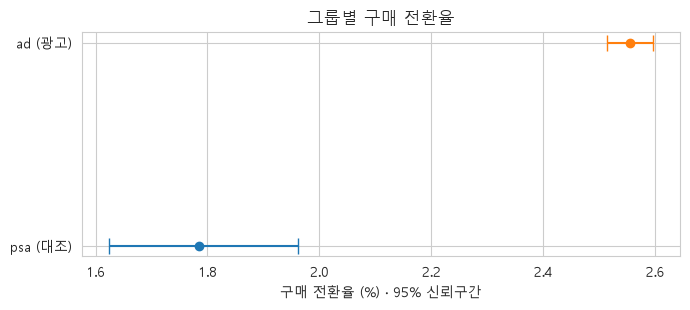

In [62]:
ci_ad  = proportion_confint(c_ad,  n_ad,  method="wilson")
ci_psa = proportion_confint(c_psa, n_psa, method="wilson")
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, (r, ci) in enumerate([(p_psa, ci_psa), (p_ad, ci_ad)]):
    ax.errorbar(r*100, i, xerr=[[(r-ci[0])*100], [(ci[1]-r)*100]], fmt="o", capsize=6)
ax.set_yticks([0, 1]); ax.set_yticklabels(["psa (대조)", "ad (광고)"])
ax.set_xlabel("구매 전환율 (%) · 95% 신뢰구간"); ax.set_title("그룹별 구매 전환율")
plt.tight_layout(); plt.savefig("figures/conversion_ci.png", dpi=150); plt.show()

> ### 📒 그룹별 전환율과 95% 신뢰구간
>
> | 그룹  | 전환율  | 95% 신뢰구간     | 막대 길이                 |
> |------|--------|-----------------|--------------------------|
> | ad   | 2.55%  | 약 2.51 ~ 2.60% | **아주 짧음** (56만 명)    |
> | psa  | 1.79%  | 약 1.62 ~ 1.96% | **약 4배 김** (2만 4천 명) |
>
> | 점의 위치      | 각 그룹의 전환율 (점추정) | ad가 오른쪽 = 전환율이 더 높음                |
> | 막대의 길이    | 추정이 얼마나 흔들리는가   | 짧을수록 정확. psa가 불확실성의 원천           |
> | 두 막대의 겹침  | 겹치지 않음             | 차이가 우연이라고 보기 어렵다는 **시각적 근거** |
>
> **** 점은 "가장 그럴듯한 값", 막대는 "이 정도 범위 안에 있을 것"이다. 막대가 길수록 덜 확실하다.
> ****
> - 보고서에서 숫자표보다 이 그림 한 장이 **"차이가 있고, 어느 쪽이 불확실한가"** 를 더 빨리 전달한다. README에 넣는 이유
> - 주의: **막대가 겹치지 않으면 유의**는 맞지만, **겹친다고 무조건 유의하지 않은 건 아니다.** 최종 판단은 차이의 신뢰구간(+0.60 ~ +0.94%p)으로 한다.
> - 여기서는 각 그룹의 구간에 **Wilson 방법**을 썼다. 전환율이 0에 가까울 때 단순 신뢰구간 공식보다 정확하다.
> - **신뢰구간 공식(Wald: 전환율 ± 1.96 × 표준오차)**. 전환율이 0에 가까우면 이 공식은 범위가 **0 아래(음수)까지** 뻗을 수 있는데(예: 100명 중 1명 → −0.95% ~ 2.95%), Wilson은 **0이라는 벽을 고려해** 0~100% 안에서 현실적인 범위를 만든다(같은 예: 0.18% ~ 5.45%).
>
> **🔁**
> - **신뢰구간의 95%** "이 방법으로 만든 구간의 95%가 참값을 포함한다".
> - **표준오차 ∝ 1/√n** → 사람이 적은 psa의 막대가 길다. "정확도는 가장 작은 집단이 정한다."
> - **0이라는 벽** → 전환율이 0에 가까우면 단순 공식이 부정확해서 Wilson을 쓴다.
>
> **** 두 점은 떨어져 있고, psa 쪽이 더 흔들린다.

> ✍️ **보고 문장** 광고군의 전환율이 더 높았다(2.55% vs 1.79%). +0.77%p (95% CI [+0.60, +0.94]), 상대 1.43배, z = 7.37, p < .001, Cramér's V = 0.010.
>
> ❓ **내가 물어볼 질문** 차이가 유의한가? 그리고 **효과크기는 큰가 작은가?** 표본이 크면 작은 차이도 유의해진다. 그래서 다음 단계에서 **돈이 되는지**를 따로 본다.
> 차이는 **유의하다**(p < .001, 신뢰구간이 0을 포함하지 않음). 하지만 효과크기는 **아주 작다**(V = 0.010). 유의하지만 작은 효과이므로, 도입 여부는 **5단계 비용 분석**으로 판단한다.

> ### 📒
>
> 광고군의 전환율이 더 높았다(2.55% vs 1.79%). +0.77%p (95% CI [+0.60, +0.94]), 상대 1.43배, z = 7.37, p < .001, Cramér's V = 0.010.
>
> ####
>
> | +0.77%p               | 두 전환율의 차이 (점추정)         | 얼마나 차이 나나             
> | 95% CI [+0.60, +0.94] | 차이가 있을 법한 범위             | 그 추정이 얼마나 불확실한가   
> | 상대 1.43배            | 대조군 대비 몇 배인가             | 상대적으로 얼마나 커졌나     
> | z = 7.37              | 차이가 흔들림(표준오차)의 몇 배인가 | 우연의 흔들림보다 얼마나 큰가 
> | p < .001              | 차이가 없다면 이런 결과가 나올 확률 | 우연인가                     
> | Cramér's V = 0.010    | 관계의 세기 (0~1)                | 그 차이가 큰 차이인가         
>
> ####
>
> | 표기 규칙              | 이유                                                       |
> |-----------------------|------------------------------------------------------------|
> | p < .001              | 아주 작은 p는 정확한 자릿수가 무의미. 0.001보다 작다면 충분       |
> | .001 (앞의 0 생략)     | p·V처럼 **1을 넘을 수 없는 값**은 앞의 0을 빼는 관례 (APA 양식) |
> | CI는 대괄호 [하한, 상한] | 범위                                                       |
> | 차이는 출력값 그대로     | 반올림한 전환율끼리 빼면 오차 (0.76 ≠ 0.77)                    |
>
> - 점추정 · 95% 신뢰구간 · 효과크기** 와 **절대·상대 차이**가 모두 들어 있다.
> - 순서는 **크기 → 불확실성 → 유의성 → 효과크기**. 읽는 사람이 "얼마나 → 얼마나 확실한가 → 우연인가 → 큰가"를 차례로 판단할 수 있다.
> - 표기는 한 가지로 **통일**한다. APA 관례를 따르면 V도 `.010`으로 쓰지만, `0.010`으로 쓴다면 보고서 전체에서 같은 방식으로 맞춘다.
>
> **🔁**
> - **p값은 "우연인가"만** 말한다. "얼마나 큰가"는 점추정·신뢰구간·효과크기의 몫이다.
> - **χ² = z²** → 7.37² ≈ 54.3. 두 비율 z-검정과 2×2 카이제곱은 같은 결론이다.
> - **상대 차이만 쓰면 과장**, 절대 차이만 쓰면 작아 보인다. 그래서 둘 다 쓴다.
>
> **** 좋은 보고 문장은 **"얼마나, 얼마나 확실하게, 우연이 아닌지, 큰지"** 를 한 줄에 담는다.

## 5. 마케팅 의사결정 — 비용 민감도 분석 (한 걸음 더 · D)

**무엇을** 전환 1건의 이익과 광고 노출 비용을 **가정**하고, 손익분기 상승폭과 추가 이익을 계산합니다.
**왜** "유의하다"는 "우연이 아니다"일 뿐 "돈이 된다"가 아닙니다. 실제 광고비·이익 데이터가 없으므로 ROI를 확정할 수 없고, 대신 **어떤 조건에서 광고가 유리한지**를 보여 줍니다.
**어떻게 해석** 2단계에서 정한 의사결정 규칙에 그대로 대입합니다.

> ❓ **내가 물어볼 질문** 전환 1건의 이익은 얼마로 가정할까? 노출 1회 비용은? 신뢰구간 **하한**에서도 이익인가? 가정을 바꾸면 결론이 뒤집히는가?

In [63]:
# ── 기준 가정 (근거를 보고서에 적고, 아래 민감도 표에서 바꿔 봄) ──
VALUE_PER_CONV = 30.0     # 전환 1건의 이익(달러)
COST_PER_AD    = 0.002    # 광고 노출 1회 비용(달러) = CPM 2달러

total_ads_ad   = df.loc[df.test_group == "ad", "total_ads"].sum()
ad_cost        = total_ads_ad * COST_PER_AD
breakeven_lift = ad_cost / (VALUE_PER_CONV * n_ad)      # 이만큼 전환율이 올라야 본전

def profit(l, value=VALUE_PER_CONV, cost=COST_PER_AD):
    return l * n_ad * value - total_ads_ad * cost

print(f"광고 비용 합계      ${ad_cost:,.0f}")
print(f"손익분기 상승폭     {breakeven_lift*100:.3f}%p\n")
for name, l in [("CI 하한", lo), ("점추정", lift), ("CI 상한", hi)]:
    print(f"{name:6s} {l*100:+.3f}%p → 추가 이익 ${profit(l):,.0f}")

광고 비용 합계      $28,029
손익분기 상승폭     0.165%p

CI 하한  +0.595%p → 추가 이익 $72,763
점추정    +0.769%p → 추가 이익 $102,260
CI 상한  +0.943%p → 추가 이익 $131,757


> ### 📒 비용 분석: 유의함을 돈의 언어로
>
> #### 계산의 흐름
>
> | 단계             | 계산                                     | 값      |
> |-----------------|------------------------------------------|---------|
> | ① 광고비         | 광고군 노출 수 합계 × 노출 1회 비용 ($0.002) | $28,029 |
> | ② 손익분기 상승폭 | 광고비 ÷ (전환 가치 $30 × 광고군 인원)       | 0.165%p |
> | ③ 추가 이익      | 상승폭 × 광고군 인원 × $30 − 광고비          | 아래 표 |
>
> #### 추가 이익

> | 시나리오         | 상승폭    | 추가 이익 | 손익분기(0.165%p)와 비교 |
> |----------------|---------- |---------|----------------------- |
> | CI 하한 (보수적) | +0.595%p | $72,763  | **약 3.6배** 넘음       |
> | 점추정          | +0.769%p | $102,260 | 약 4.7배 넘음           |
> | CI 상한 (낙관적) | +0.943%p | $131,757 | 약 5.7배 넘음           |
>
> **손익분기 상승폭** 광고비 대비 전환율이 최소 0.165%p는 올라야 한다. 실제로는 보수적으로 봐도 0.595%p 올랐다.
>
> #### 이 숫자를 어디까지 믿나
>
> - **$30과 CPM $2는 내가 정한 가정**이다. 실제 이익률·광고 단가를 모르므로, 이 표는 "확정 ROI"가 아니라 **"이 조건이라면"** 의 계산이다. 그래서 다음 민감도 표가 필수다.
> - 보고서에는 가정값과 **그렇게 정한 근거**(예: 업계 평균 CPM, 평균 주문 이익)를 함께 적는다.
> - 광고비는 **광고군 노출분만** 계산했다. 공익광고 자리의 비용이나 기회비용은 넣지 않았다는 점도 한계로 남긴다.
> - 2단계에서 미리 정한 규칙에 대입하면: 유의함 + **하한(0.595) ≥ 손익분기(0.165)** → 기준 가정 하 **출시**.
>
> **🔁**
> - **유의하다 ≠ 돈이 된다.** p값은 우연인가를, 비용 분석은 이익인가를 판단한다(실질적 유의성).
> - **신뢰구간 하한으로 판단**하는 이유: 돈을 쓰는 결정은 보수적인 값이 기준을 넘을 때 한다.
> - **효과크기가 작아도(V = 0.010)** 규모(56만 명)가 곱해지면 큰 이익이 될 수 있다.
>
> **** 기준 가정에서는 나쁘게 봐도 본래 광고비의 3.6배다. 이제 **가정을 흔들어도** 이 결론이 버티는지 본다.

> #### 🔁 ROI
>
> **ROI(Return On Investment, 투자수익률)** = (번 돈 − 쓴 돈) ÷ 쓴 돈 × 100%
> "광고비 1달러를 쓰면 몇 달러가 **남는가**"를 묻는 지표. 100%면 1달러 써서 1달러 남김, 0%면 광고비 회수, 음수면 손해.
>
> #### 작은 효과 × 큰 규모 = 큰 이익 (직접 곱해 보기)
>
> | 단계            | 계산 (점추정 기준)                | 값             |
> |----------------|---------------------------------|----------------|
> | ① 추가 구매 건수 | 상승폭 0.769%p × 광고군 564,577명 | 약 **4,343건**  |
> | ② 추가 매출이익  | 4,343건 × 전환 1건 이익 $30      | 약 **$130,289** |
> | ③ 순이익        | $130,289 − 광고비 $28,029       | **$102,260**    |
> | ④ ROI          | $102,260 ÷ $28,029             | 약 **365%**     |
>
> | 시나리오  | 추가 구매  | 순이익     | ROI     |
> |----------|-----------|----------|---------|
> | CI 하한  | 약 3,360건 | $72,763  | 약 260% |
> | 점추정   | 약 4,343건 | $102,260 | 약 365% |
> | CI 상한  | 약 5,326건 | $131,757 | 약 470% |
>
> **** 한 사람에게는 100명당 0.77명이라는 **아주 작은 차이**지만, 56만 명에게 곱하면 **4천 건이 넘는 추가 구매**가 된다. 효과크기(V = 0.010)는 "한 사람의 구매를 얼마나 설명하나"를, 이익은 "전체에 곱했을 때 얼마인가"를 말한다.
>
> **** 보수적으로 봐도(CI 하한) ROI 약 260%, 즉 광고비 1달러당 약 2.6달러가 남는다. 단, $30과 CPM $2는 **가정값**이라 ROI도 가정 위의 숫자다. 마케팅 보고에서는 ROI 하나보다 **"하한 기준 ROI"** 를 함께 보여 주는 게 정직하다.
>
> **** 효과크기는 **개인 단위의 크기**, ROI는 **규모를 곱한 돈의 크기**다. 둘은 다른 질문에 답한다.

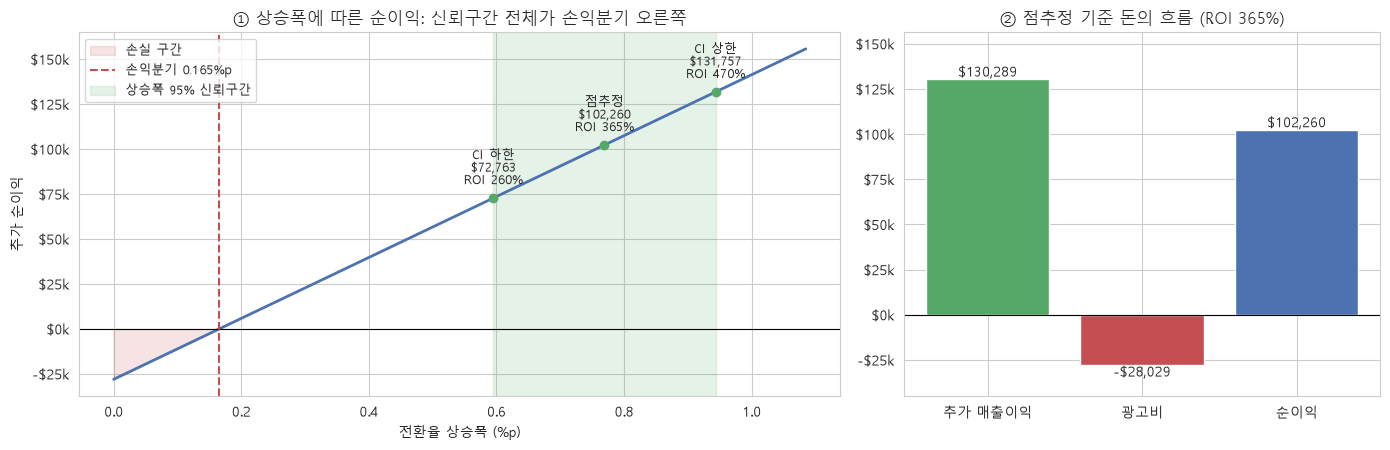

In [64]:
# 비용 분석 시각화: 상승폭에 따른 순이익과 ROI
money = lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"
money_k = plt.FuncFormatter(lambda v, _: f"-${abs(v)/1000:,.0f}k" if v < 0 else f"${v/1000:,.0f}k")
pts = [("CI 하한", lo), ("점추정", lift), ("CI 상한", hi)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})

# ① 상승폭 → 순이익 (손익분기선 · 신뢰구간 · 세 시나리오)
ax = axes[0]
x = np.linspace(0, hi * 1.15, 200)
y = np.array([profit(v) for v in x])
ax.plot(x * 100, y, color="#4C72B0", lw=2)
ax.axhline(0, color="black", lw=0.8)
ax.fill_between(x * 100, y, 0, where=y < 0, color="#C44E52", alpha=0.15, label="손실 구간")
ax.axvline(breakeven_lift * 100, color="#C44E52", ls="--", label=f"손익분기 {breakeven_lift*100:.3f}%p")
ax.axvspan(lo * 100, hi * 100, color="#55A868", alpha=0.15, label="상승폭 95% 신뢰구간")
for name, v in pts:
    p = profit(v)
    ax.scatter(v * 100, p, color="#55A868", zorder=3)
    ax.annotate(f"{name}\n{money(p)}\nROI {p / ad_cost:.0%}", (v * 100, p),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_xlabel("전환율 상승폭 (%p)"); ax.set_ylabel("추가 순이익")
ax.set_title("① 상승폭에 따른 순이익: 신뢰구간 전체가 손익분기 오른쪽")
ax.yaxis.set_major_formatter(money_k)
ax.legend(loc="upper left", fontsize=9)

# ② 점추정 기준 돈의 흐름: 추가 매출이익 → 광고비 → 순이익
ax = axes[1]
gross = lift * n_ad * VALUE_PER_CONV
vals = [gross, -ad_cost, gross - ad_cost]
ax.bar(["추가 매출이익", "광고비", "순이익"], vals, color=["#55A868", "#C44E52", "#4C72B0"])
for i, v in enumerate(vals):
    ax.text(i, v, money(v), ha="center", va="bottom" if v >= 0 else "top")
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"② 점추정 기준 돈의 흐름 (ROI {(gross - ad_cost) / ad_cost:.0%})")
ax.yaxis.set_major_formatter(money_k)
ax.set_ylim(-ad_cost * 1.6, gross * 1.2)

plt.tight_layout()
plt.savefig("figures/cost_analysis.png", dpi=150)
plt.show()

> **** 상승폭의 95% 신뢰구간(초록 띠) 전체가 손익분기선(0.165%p) 오른쪽에 있어, 기준 가정에서는 **나쁘게 봐도(ROI 260%) 광고비보다 훨씬 더 벌어들이는** 구조

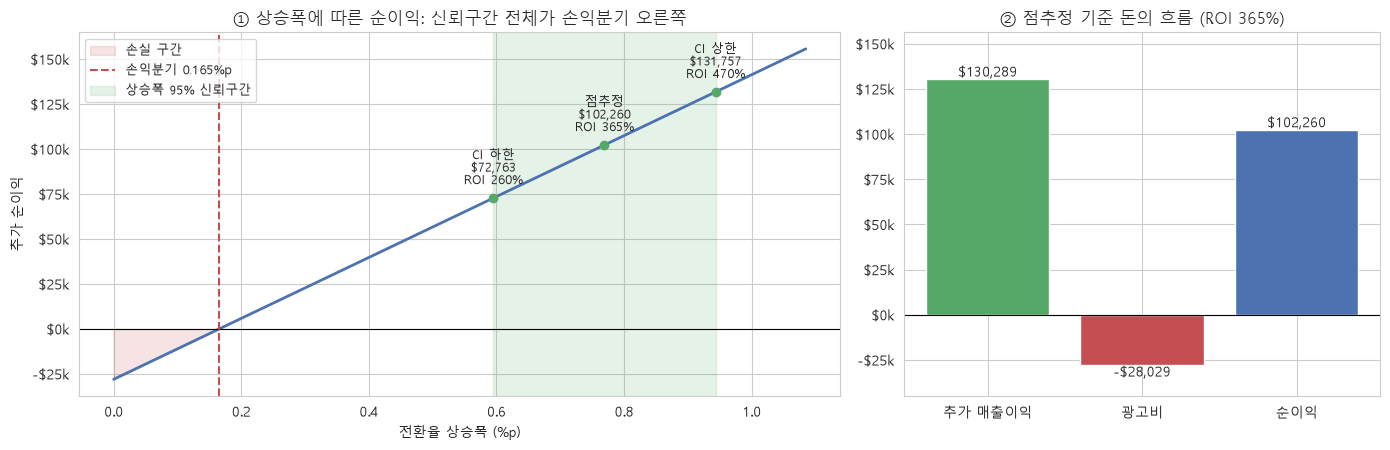

In [65]:
# 비용 분석 시각화: 상승폭에 따른 순이익과 ROI
money = lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"
money_k = plt.FuncFormatter(lambda v, _: f"-${abs(v)/1000:,.0f}k" if v < 0 else f"${v/1000:,.0f}k")
pts = [("CI 하한", lo), ("점추정", lift), ("CI 상한", hi)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})

# ① 상승폭 → 순이익 (손익분기선 · 신뢰구간 · 세 시나리오)
ax = axes[0]
x = np.linspace(0, hi * 1.15, 200)
y = np.array([profit(v) for v in x])
ax.plot(x * 100, y, color="#4C72B0", lw=2)
ax.axhline(0, color="black", lw=0.8)
ax.fill_between(x * 100, y, 0, where=y < 0, color="#C44E52", alpha=0.15, label="손실 구간")
ax.axvline(breakeven_lift * 100, color="#C44E52", ls="--", label=f"손익분기 {breakeven_lift*100:.3f}%p")
ax.axvspan(lo * 100, hi * 100, color="#55A868", alpha=0.15, label="상승폭 95% 신뢰구간")
for name, v in pts:
    p = profit(v)
    ax.scatter(v * 100, p, color="#55A868", zorder=3)
    ax.annotate(f"{name}\n{money(p)}\nROI {p / ad_cost:.0%}", (v * 100, p),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_xlabel("전환율 상승폭 (%p)"); ax.set_ylabel("추가 순이익")
ax.set_title("① 상승폭에 따른 순이익: 신뢰구간 전체가 손익분기 오른쪽")
ax.yaxis.set_major_formatter(money_k)
ax.legend(loc="upper left", fontsize=9)

# ② 점추정 기준 돈의 흐름: 추가 매출이익 → 광고비 → 순이익
ax = axes[1]
gross = lift * n_ad * VALUE_PER_CONV
vals = [gross, -ad_cost, gross - ad_cost]
ax.bar(["추가 매출이익", "광고비", "순이익"], vals, color=["#55A868", "#C44E52", "#4C72B0"])
for i, v in enumerate(vals):
    ax.text(i, v, money(v), ha="center", va="bottom" if v >= 0 else "top")
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"② 점추정 기준 돈의 흐름 (ROI {(gross - ad_cost) / ad_cost:.0%})")
ax.yaxis.set_major_formatter(money_k)
ax.set_ylim(-ad_cost * 1.6, gross * 1.2)

plt.tight_layout()
plt.savefig("figures/cost_analysis.png", dpi=150)
plt.show()

> **** 상승폭의 95% 신뢰구간(초록 띠) 전체가 손익분기선(0.165%p) 오른쪽에 있어, 기준 가정에서는 **나쁘게 봐도(ROI 260%) 광고비보다 훨씬 더 벌어들이는** 구조다.

In [66]:
# 민감도: 전환 가치 × 노출 비용 조합별 추가 이익 (점추정 기준, 달러)
values = [10, 30, 60]
cpms   = [0.001, 0.002, 0.005]
grid = pd.DataFrame({f"CPM ${c*1000:.0f}": [profit(lift, v, c) for v in values] for c in cpms},
                    index=[f"전환가치 ${v}" for v in values]).round(0)
grid

,CPM $1,CPM $2,CPM $5
전환가치 $10,29415.0,15400.0,-26644.0
전환가치 $30,116275.0,102260.0,60216.0
전환가치 $60,246564.0,232550.0,190505.0


CPM(광고단가)

> ### 📒 민감도 분석: 가정을 흔들어도 결론이 버티나
>
> | 전환 1건 이익 ↓ / 노출 비용 → | CPM $1    | CPM $2 (기준)  | CPM $5          |
> |----------------------------|-----------|---------------|-----------------|
> | $10                        | +$29,415  | +$15,400      | **−$26,644** ❌ |
> | $30 (기준)                  | +$116,275 | **+$102,260** | +$60,216        |
> | $60                        | +$246,564 | +$232,550     | +$190,505       |
>
> ****
> - **민감도 분석**은 확실하지 않은 가정값을 바꿔 가며 **결론이 뒤집히는 지점**을 찾는 일이다.
> - 9개 조합 중 **8개는 이익**, 손실은 **전환 가치가 낮고($10) 광고 단가가 비쌀 때(CPM $5)** 한 곳뿐이다.
>
> ****
> - 결론은, 대부분의 조건에서 **튼튼하다.** 다만 "싼 상품을 비싼 광고 자리에 파는" 조건에서는 손해가 난다.
> - 경계를 숫자로 말할 수 있다: CPM $5라면 전환 1건 이익이 **약 $16 이상**(보수적인 CI 하한 기준으로는 **약 $21 이상**)이어야 이익이다.
> - 이 표는 **점추정 기준**이다. CI 하한으로 다시 계산해도 손실 칸은 같은 한 곳뿐이라 결론은 그대로다.
> - 그래서 의사결정자에게는 "출시"만이 아니라 **"전환 1건 이익이 ○달러 이상인 상품에, CPM ○달러 이하의 자리라면"** 이라는 조건을 함께 전한다.
>
> **🔁**
> - **가정 위의 숫자는 가정을 흔들어 봐야 믿을 수 있다.** 인과추론에서 "가정을 먼저 검증한다"와 같은 태도
> - **신뢰구간 하한으로도 확인**한다. 돈을 쓰는 결정은 보수적인 값으로 판단한다.
> - **효과는 작아도 규모가 곱해지면 이익**이 되지만, 비용이 커지면 그 이익이 사라질 수도 있다.
>
> **** 결론은, 대부분의 조건에서 버티고, **"싼 상품 × 비싼 광고"** 에서만 뒤집힌다.

> ### 📒 광고단가 CPM과 "조건부 추천"
>
> #### 🔁 CPM 
>
> | 지표                   | 뜻                         | 예 (설명용 숫자)         |
> |-----------------------|----------------------------|------------------------|
> | CPM (Cost Per Mille)  | 광고 **1,000회 노출**당 비용 | CPM $2 = 노출 1회 $0.002 |
> | CPC (Cost Per Click)  | 광고 **클릭 1회**당 비용     | 클릭당 $0.5              |
> | CPA (Cost Per Action) | **구매 등 행동 1건**당 비용  | 구매 1건당 $8            |
>
> Mille는 라틴어로 **1,000**이다. 이 데이터에는 노출 수(`total_ads`)만 있어서, 노출 기준인 **CPM**으로 광고비를 계산했다.
>
> #### "출시"가 아니라 "이 조건이라면 출시"
>
> 광고 단가(CPM)에 따라, 광고비를 회수하려면 전환 1건이 최소 얼마의 이익을 내야 하는지가 달라진다.
>
> | 광고 단가      | 광고비      | 필요한 전환 1건 이익 (점추정) | 보수적 기준 (CI 하한) 
> |---------------|------------|---------------------------|----------------------
> | CPM $1        | 약 $14,014 | 약 $3.2 이상               | 약 **$4.2** 이상      
> | CPM $2 (기준) | 약 $28,029  | 약 $6.5 이상               | 약 **$8.3** 이상      
> | CPM $5        | 약 $70,072 | 약 $16.1 이상              | 약 **$20.9** 이상     
>
> **** 광고 단가가 비쌀수록, 전환 1건이 더 많은 이익을 내야 광고비를 회수한다. 이 경계선을 알면 "어떤 상품에, 어떤 광고 자리까지" 괜찮은지 말할 수 있다.
> **** 의사결정자는 "출시냐 아니냐"보다 **"어디까지 써도 되나"** 를 알고 싶어 한다. 그래서 결론을 조건과 함께 전한다.
> > **예시 문장** "광고는 전환율을 높였고, 보수적으로 봐도 **전환 1건 이익이 약 $21 이상인 상품이라면 CPM $5 자리까지**, **약 $8 이상이라면 CPM $2 자리까지** 광고비보다 더 벌어들인다."

> **** **🔁광고 "자리"** 광고 노출 위치의 의미
> "자리"는 광고가 실제로 노출되는 위치. 마케팅 업계에서는 광고 지면 또는 인벤토리라고도 부른다. 예를 들면 포털 첫 화면 배너, 기사 중간 배너, 앱 피드 사이의 광고 칸 같은 곳.
> 자리마다 단가가 다르다. 사람이 많이 보는 포털 첫 화면은 비싸고(CPM이 높고), 덜 보는 페이지 하단은 싸요(CPM이 낮다). "CPM $2 자리까지"는 "1,000회 노출에 $2 이하인 광고 위치까지는 이익"이라는 뜻. psa 그룹이 공익광고를 본 "같은 자리"도 이 의미.
>
> **🔁**
> - **손익분기**: 광고비를 회수하는 경계. 경계를 넘으면 이익, 못 넘으면 손실.
> - **보수적 기준(CI 하한)**: 돈을 쓰는 결정은 나쁘게 봐도 성립하는지로 판단한다.
> - **민감도 분석**: 가정값을 흔들어 결론이 뒤집히는 지점을 찾고, 그 지점을 **조건**으로 바꿔 전한다.
>
> **** 좋은 추천은 "예/아니오"가 아니라 **"이 조건까지는 예"** 다.

In [67]:
# 2단계에서 미리 정한 의사결정 규칙 적용
significant = p_z < ALPHA
if significant and lo >= breakeven_lift:
    decision = "출시"
elif significant and lift >= breakeven_lift:
    decision = "추가 수집"
else:
    decision = "보류"
print(f"유의성: {'유의' if significant else '유의하지 않음'} | 손익분기 {breakeven_lift*100:.3f}%p | "
      f"CI 하한 {lo*100:.3f}%p | 점추정 {lift*100:.3f}%p")
print("→ 기준 가정 하 의사결정:", decision)

유의성: 유의 | 손익분기 0.165%p | CI 하한 0.595%p | 점추정 0.769%p
→ 기준 가정 하 의사결정: 출시


> ### 📒 시작할 때 미리 정한 규칙으로 내린 결정
>
> | 점검 순서           | 결과               | 통과     
> |--------------------|-------------------|----------
> | ① 차이가 유의한가    | p < .001          | ✅       
> | ② 점추정 ≥ 손익분기  | 0.769%p ≥ 0.165%p | ✅       
> | ③ CI 하한 ≥ 손익분기 | 0.595%p ≥ 0.165%p | ✅       
> | → 결정             | 세 조건 모두 충족    | **출시** 
>
> **** 결정은 **2단계에서 결과를 보기 전에 정한 규칙**을 그대로 적용해 나왔다. 숫자를 본 뒤 기준을 고르지 않았기 때문에, 원하는 결론에 맞춘 결정이 아니다.
>
> ****
> - 결정문에는 항상 **조건**이 붙는다: "**기준 가정(전환 1건 이익 $30, CPM $2) 하에서**, 그리고 **배정이 적절했다는 전제 하에서** 출시."
> - 민감도 분석상 **"싼 상품 × 비싼 광고"(전환 $10, CPM $5)** 에서는 손실이므로, 실제 집행 시 상품의 이익률과 광고 단가를 먼저 확인한다.
> - 보수적 기준으로 **전환 1건 이익 약 $8 이상이면 CPM $2 자리까지, 약 $21 이상이면 CPM $5 자리까지** 이익이다.
>
> **🔁**
> - **가설처럼 결정 기준도 미리 고정**한다. 결과를 보고 기준을 바꾸면 p-해킹과 같은 함정이다.
> - **유의함 → 돈이 됨 → 나쁘게 봐도 돈이 됨**, 세 단계를 차례로 통과해야 출시다.
> - 결론은 **"이 조건에서 이만큼 말할 수 있다"** 로 전한다.
>
> **최종 결정 문장** 광고는 공익광고 대비 구매 전환율을 +0.77%p(95% CI [+0.60, +0.94]) 높였고, 기준 가정 하에서 신뢰구간 하한(0.595%p)조차 손익분기(0.165%p)를 넘으므로 **출시**를 제안한다. 단, 전환 1건 이익이 낮고 광고 단가가 높은 조건에서는 손실이 날 수 있다.

## 6. 보고서 요약 (README와 같은 흐름)

1. **질문과 가설** — 광고가 공익광고 대비 구매 전환율을 바꾸는가? H₀: 같다 / H₁: 다르다, α = 0.05, 양측.
2. **데이터 점검** — 정제 전 __행 → 후 __행. 결측 __, 중복 __. 배정 ad __% : psa __%, 원래 계획 정보가 없어 SRM 판정 유보.
3. **검정 선택** — 비율 지표 · 2집단 → 두 비율 z-검정(= 카이제곱). 모든 칸 도수 충분.
4. **결과** — __%p (95% CI [__, __]), 상대 __배, p = __, Cramér's V = __.
5. **의사결정** — 기준 가정(전환 $__, CPM $__) 하 **____**. 민감도: ____ 조건에서는 결론이 바뀜.
6. **한계** — 무작위 배정 절차를 독립적으로 검증할 수 없음(적절했다는 전제), SRM 판정 유보, 대조군이 작음, 비용·이익은 가정값, 단기 전환만 측정, 수집 시기·지역 정보 없음, 노출 요일·시간·횟수는 처치 이후 변수라 원인으로 해석하지 않음.

## 6. 보고서 요약 (README와 같은 흐름)

1. **질문과 가설** — 광고가 공익광고 대비 구매 전환율을 바꾸는가? H₀: 같다 / H₁: 다르다, α = 0.05, 양측.
2. **데이터 점검** — 정제 전 588,101행 → 후 588,101행(제외 0행). 결측 0, 중복 사용자 0, 이상 라벨·범위 밖 값 없음. 배정 ad 96.0%(564,577명) : psa 4.0%(23,524명), 원래 계획 정보가 없어 SRM 판정 유보. 노출 수는 두 그룹이 사실상 같음(평균 24.8회, 중앙값 13 vs 12회).
3. **검정 선택** — 비율 지표 · 2집단 → 두 비율 z-검정(= 카이제곱). 가장 작은 칸(psa 구매자)도 420명으로 모든 칸 도수 충분.
4. **결과** — 전환율 ad 2.55% vs psa 1.79%. +0.77%p (95% CI [+0.60, +0.94]), 상대 1.43배(+43%), z = 7.37, p < .001, Cramér's V = 0.010. **유의하지만 효과크기는 작음.**
5. **의사결정** — 기준 가정(전환 1건 이익 $30, CPM $2) 하 **출시**. 손익분기 0.165%p를 CI 하한 0.595%p도 넘음(하한 기준 순이익 약 $72,763, ROI 약 260%). 민감도: **전환 1건 이익 $10 × CPM $5** 조건에서는 손실로 결론이 바뀜. 보수적 기준으로 전환 1건 이익이 약 $8 이상이면 CPM $2, 약 $21 이상이면 CPM $5 노출 위치까지 이익.
6. **한계** — 무작위 배정 절차를 독립적으로 검증할 수 없음(적절했다는 전제), SRM 판정 유보, 대조군이 작음(약 4%, 불확실성의 대부분이 대조군에서 옴), 비용·이익은 가정값, 광고비는 광고군 노출분만 계산(공익광고 자리의 비용·기회비용 미포함), 단기 전환만 측정, 수집 시기·지역 정보 없음, 노출 요일·시간·횟수는 처치 이후 변수라 원인으로 해석하지 않음.

> ### 📒 분석 전체를 하나의 이야기로
>
> | 항목          | 답하는 질문                | 핵심 한 줄                          
> |--------------|---------------------------|----------------------------------
> | 1 질문과 가설  | 무엇을 알고 싶었나          | 결과를 보기 **전에** 고정           
> | 2 데이터 점검  | 데이터를 믿어도 되나        | 제외 0행, SRM은 판정 유보          
> | 3 검정 선택   | 왜 그 검정인가              | 0/1 비율 · 2집단 → 두 비율 z-검정(카이제곱)   
> | 4 결과       | 얼마나, 얼마나 확실하게, 큰가 | +0.77%p, 유의하지만 효과크기는 작음 
> | 5 의사결정    | 그래서 할까 말까            | 기준 가정 하 출시, 단 조건부        
> | 6 한계       | 어디까지 믿어도 되나         | 가정·전제·측정하지 못한 것          
>
> **** 여섯 항목은 따로 노는 체크리스트가 아니라 **하나의 이야기**다. 질문을 세우고 → 데이터를 믿을 수 있는지 확인하고 → 맞는 도구를 고르고 → 답을 구하고 → 결정하고 → 그 결정이 어디까지 유효한지 밝힌다.

> - **판정하려면** 계획 비율이 있어야 한다. 계획과 실제를 비교해 **p가 크면 정상**이다(평소 검정과 해석 방향이 반대).
> - **이 데이터는** 계획 비율 정보가 없어 비교할 기준이 없다. 실제 비율(96:4)로 기대 비율을 만들면 순환논리라 **판정 유보**했다.
> - **그래서** 결론에 "배정이 적절했다는 **전제 하에서**"를 붙인다.
>
> **** 기준(계획)이 없으면 판정(SRM)도 없다. 모르는 건 모른다고 기록한다.

>#### 🔁 SRM
>
> **SRM(Sample Ratio Mismatch, 표본 비율 불일치)** = 계획한 배정 비율과 실제 비율이 **어긋난 것**. 배정 버그나 데이터 누락의 신호라서, A/B 테스트에서는 결과를 보기 **전에** 먼저 확인한다.
>
> ****
> - 의사결정자는 보통 **4번(결과)과 5번(결정)** 만 먼저 읽는다. 그래서 README 맨 위에 **한 줄 결론**을 따로 둔다.
> - 그 결론을 믿게 만드는 건 **2번(점검)과 6번(한계)** 이다. "무조건 확실합니다"보다 **"이 조건에서 이만큼 말할 수 있습니다"** 가 더 신뢰받는다.
> - 숫자는 **출력값 그대로**, 표기는 **한 가지로 통일**한다(p < .001, CI는 [하한, 상한]).
>
> **🔁**
> - **가설과 결정 기준은 결과 전에 고정** (p-해킹 방지)
> - **검정 방법은 결과 변수의 형태로** 고른다 (0/1 → 두 비율 검정)
> - **유의하다 ≠ 중요하다 ≠ 돈이 된다** (p값 · 효과크기 · 비용 분석은 각자 다른 질문에 답함)
> - **인과 해석에는 전제가 붙는다** (배정이 적절했다는 전제 하에서)
>
> **** 좋은 분석 보고는 **질문에서 시작해 한계로 끝난다.**